In [9]:
!rm -rf /content/drive

In [10]:
# ============================================================
# DR MODULE — NOTEBOOK 03: HYPERPARAMETER OPTIMIZATION
# Focus: Label Smoothing, Regularization, and Overfitting Control
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import densenet121
import numpy as np
import sys

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Base and Outputs directory mapping based on your Drive structure
BASE = Path("/content/drive/MyDrive/Major_Project/Diabetic_Retinopathy")
OUTPUT_DIR = BASE / "outputs"
V2_DIR = OUTPUT_DIR / "v2"
MODEL_DIR = V2_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
OPT_DIR = V2_DIR / "optimization"
OPT_DIR.mkdir(parents=True, exist_ok=True)

# Load CSV files directly from the outputs folder
train_df = pd.read_csv(OUTPUT_DIR / "dr_train.csv")
val_df = pd.read_csv(OUTPUT_DIR / "dr_val.csv")

print("Train samples loaded:", len(train_df))
print("Val samples loaded:", len(val_df))

# Import V2 Preprocessing module from outputs/v2
sys.path.insert(0, str(V2_DIR))
from dr_preprocessing_v2 import preprocess_dr_v2

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class DROptDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = preprocess_dr_v2(row["image_path"])
        label = int(row["classe"])
        if self.transform:
            img = self.transform(img)
        return img, label

train_loader = DataLoader(DROptDataset(train_df, train_transform), batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(DROptDataset(val_df, val_transform), batch_size=16, shuffle=False, num_workers=2)

# Optimized Model Setup with Label Smoothing (0.1) & Stronger Regularization
model = densenet121(weights="DEFAULT")
model.classifier = nn.Linear(model.classifier.in_features, 5)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=5e-5,          # Lower learning rate for stable fine-tuning
    weight_decay=1e-3 # Higher weight decay to prevent validation loss divergence
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

print("Drive mounted and Optimized DenseNet-121 initialized successfully with L4 GPU & Label Smoothing!")

Mounted at /content/drive
Train samples loaded: 2094
Val samples loaded: 445
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 234MB/s]


Drive mounted and Optimized DenseNet-121 initialized successfully with L4 GPU & Label Smoothing!


Starting Optimized DenseNet-121 Training on cuda ...



Epoch 01/15 [Train]:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch 01/15 [Val]:   0%|          | 0/28 [00:00<?, ?it/s]

Epoch 01/15 | Train Loss: 1.3430 | Train Acc: 0.4379 | Val Loss: 1.1937 | Val Acc: 0.5146 | Val Macro F1: 0.4957 | Val AUROC: 0.8481
  --> Saved new best optimized checkpoint (Val Macro F1: 0.4957)


Epoch 02/15 [Train]:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch 02/15 [Val]:   0%|          | 0/28 [00:00<?, ?it/s]

... (14 outputs left out)

Epoch 06/15 | Train Loss: 0.9656 | Train Acc: 0.6882 | Val Loss: 1.1645 | Val Acc: 0.5393 | Val Macro F1: 0.5450 | Val AUROC: 0.8614


Epoch 07/15 [Train]:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch 07/15 [Val]:   0%|          | 0/28 [00:00<?, ?it/s]

Epoch 07/15 | Train Loss: 0.9402 | Train Acc: 0.7125 | Val Loss: 1.1434 | Val Acc: 0.5528 | Val Macro F1: 0.5582 | Val AUROC: 0.8661

Early stopping triggered at epoch 7.


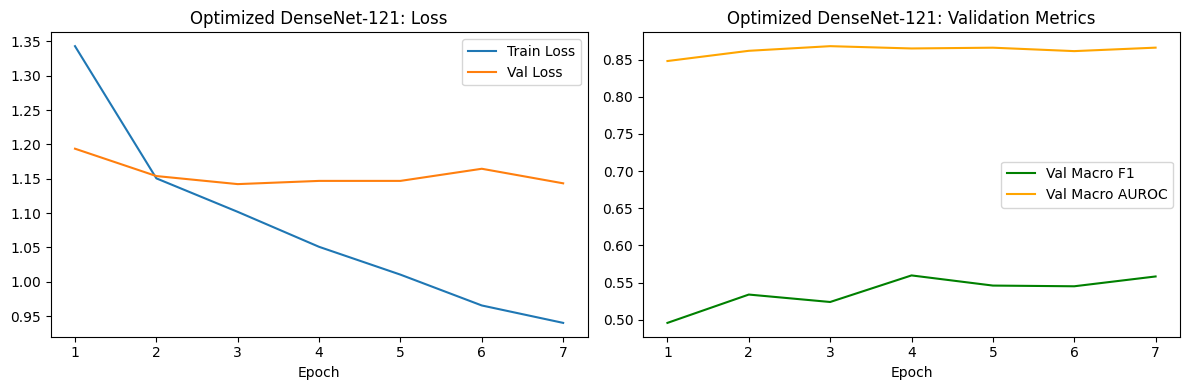


Loading best optimized checkpoint for Held-Out Test Evaluation...

OPTIMIZED DENSENET-121 — HELD-OUT TEST METRICS (n=460)
                                                Model  Test Samples  Accuracy  Balanced Acc  Macro Precision  Macro Recall  Macro F1  Macro OvR AUROC  Multiclass Brier
DenseNet-121 (Optimized: Label Smoothing 0.1 + AdamW)           460    0.5239        0.5159           0.5206        0.5159    0.5079            0.845            0.5777


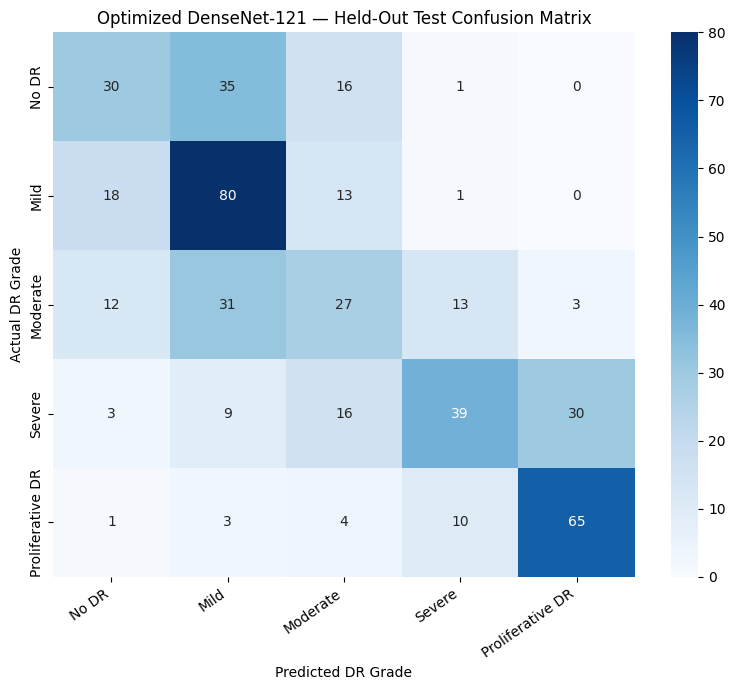


All optimization artifacts saved to: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/v2/optimization


In [11]:
# ============================================================
# DR MODULE — NOTEBOOK 03: TRAINING, VALIDATION & TEST EVALUATION
# ============================================================

import json
import copy
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

# 1. Training Configuration
EPOCHS = 15
PATIENCE = 3
NUM_CLASSES = 5
CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "Proliferative DR"]

best_val_f1 = -1.0
epochs_without_improvement = 0
history = []

CHECKPOINT_PATH = OPT_DIR / "dr_optimized_densenet121_best.pth"

print("Starting Optimized DenseNet-121 Training on", DEVICE, "...\n")

for epoch in range(1, EPOCHS + 1):
    # --- Training Phase ---
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Train]", leave=False)
    for images, labels in train_bar:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += batch_size

        train_bar.set_postfix(
            loss=f"{train_loss_sum / train_total:.4f}",
            acc=f"{train_correct / train_total:.4f}"
        )

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # --- Validation Phase ---
    model.eval()
    val_loss_sum = 0.0
    val_labels, val_probs = [], []

    val_bar = tqdm(val_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Val]", leave=False)
    with torch.inference_mode():
        for images, labels in val_bar:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            probs = torch.softmax(outputs.float(), dim=1)
            val_loss_sum += loss.item() * labels.size(0)
            val_labels.append(labels.cpu().numpy())
            val_probs.append(probs.cpu().numpy())

    val_labels = np.concatenate(val_labels)
    val_probs = np.concatenate(val_probs)
    val_preds = np.argmax(val_probs, axis=1)

    val_loss = val_loss_sum / len(val_loader.dataset)
    val_acc = accuracy_score(val_labels, val_preds)
    val_f1 = f1_score(val_labels, val_preds, average="macro", zero_division=0)
    val_auc = roc_auc_score(
        val_labels, val_probs, multi_class="ovr", average="macro", labels=list(range(NUM_CLASSES))
    )

    scheduler.step()

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "val_macro_f1": val_f1,
        "val_macro_auroc": val_auc
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f} | Val AUROC: {val_auc:.4f}"
    )

    # Save best model checkpoint based on Macro F1
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        epochs_without_improvement = 0
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print(f"  --> Saved new best optimized checkpoint (Val Macro F1: {best_val_f1:.4f})")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch}.")
        break

# 2. Save Training History & Curves
history_df = pd.DataFrame(history)
history_df.to_csv(OPT_DIR / "dr_optimized_training_history.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Val Loss")
axes[0].set_title("Optimized DenseNet-121: Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["val_macro_f1"], label="Val Macro F1", color="green")
axes[1].plot(history_df["epoch"], history_df["val_macro_auroc"], label="Val Macro AUROC", color="orange")
axes[1].set_title("Optimized DenseNet-121: Validation Metrics")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(OPT_DIR / "dr_optimized_training_curves.png", dpi=200)
plt.show()

# 3. Held-Out Test Set Evaluation (N = 460)
print("\nLoading best optimized checkpoint for Held-Out Test Evaluation...")
test_df = pd.read_csv(OUTPUT_DIR / "dr_test.csv")
test_loader = DataLoader(DROptDataset(test_df, val_transform), batch_size=16, shuffle=False, num_workers=2)

model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True))
model.eval()

y_true, y_probs = [], []
with torch.inference_mode():
    for imgs, lbls in test_loader:
        imgs = imgs.to(DEVICE)
        logits = model(imgs)
        probs = torch.softmax(logits.float(), dim=1)
        y_true.extend(lbls.numpy())
        y_probs.extend(probs.cpu().numpy())

y_true = np.array(y_true)
y_probs = np.array(y_probs)
y_pred = np.argmax(y_probs, axis=1)
y_onehot = np.eye(NUM_CLASSES)[y_true]

opt_test_metrics = {
    "Model": "DenseNet-121 (Optimized: Label Smoothing 0.1 + AdamW)",
    "Test Samples": int(len(y_true)),
    "Accuracy": round(accuracy_score(y_true, y_pred), 4),
    "Balanced Acc": round(balanced_accuracy_score(y_true, y_pred), 4),
    "Macro Precision": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
    "Macro Recall": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
    "Macro F1": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
    "Macro OvR AUROC": round(roc_auc_score(y_true, y_probs, multi_class="ovr", average="macro", labels=list(range(NUM_CLASSES))), 4),
    "Multiclass Brier": round(np.mean(np.sum((y_probs - y_onehot) ** 2, axis=1)), 4)
}

print("\n" + "="*80)
print("OPTIMIZED DENSENET-121 — HELD-OUT TEST METRICS (n=460)")
print("="*80)
print(pd.DataFrame([opt_test_metrics]).to_string(index=False))
print("="*80)

pd.DataFrame([opt_test_metrics]).to_csv(OPT_DIR / "dr_optimized_test_metrics.csv", index=False)
with open(OPT_DIR / "dr_optimized_test_metrics.json", "w") as f:
    json.dump(opt_test_metrics, f, indent=2)

# 4. Save Confusion Matrix & Test Predictions (for Multimodal Fusion)
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted DR Grade")
plt.ylabel("Actual DR Grade")
plt.title("Optimized DenseNet-121 — Held-Out Test Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(OPT_DIR / "dr_optimized_confusion_matrix.png", dpi=200)
plt.show()

pred_df = pd.DataFrame({
    "image_path": test_df["image_path"].tolist(),
    "true_grade": y_true,
    "predicted_grade": y_pred
})
for c in range(NUM_CLASSES):
    pred_df[f"prob_grade_{c}"] = y_probs[:, c]
pred_df.to_csv(OPT_DIR / "dr_optimized_test_predictions.csv", index=False)

print(f"\nAll optimization artifacts saved to: {OPT_DIR}")

Active clinical metadata columns: ['age', 'sexe', 'type_diabete']
Processed clinical metadata feature dim: 5

Extracting 1024-dim retinal embeddings from Optimized DenseNet-121...

Fusion training complete! Best Validation Macro AUROC: 0.8650

DR MULTIMODAL FUSION — HELD-OUT TEST METRICS (n=460)
                                               Model  Test Samples  Accuracy  Balanced Acc  Macro Precision  Macro Recall  Macro F1  Macro OvR AUROC  Multiclass Brier
DenseNet-121 + Clinical Metadata (Multimodal Fusion)           460    0.5239        0.5269           0.5177        0.5269    0.5204           0.8349            0.6074


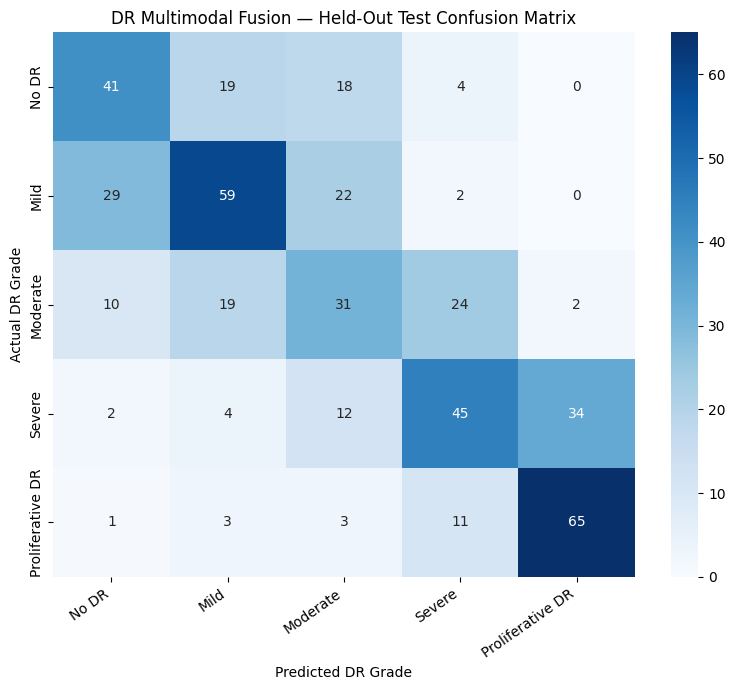


All fusion artifacts saved to: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/v2/fusion


In [12]:
# ============================================================
# DR MODULE — MULTIMODAL FUSION (IMAGE + CLINICAL METADATA)
# Run directly below Optimization in the same notebook
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import transforms
from torchvision.models import densenet121

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix
)

# 1. Setup Fusion Output Directory & Load Splits
FUSION_DIR = V2_DIR / "fusion"
FUSION_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(OUTPUT_DIR / "dr_train.csv")
val_df = pd.read_csv(OUTPUT_DIR / "dr_val.csv")
test_df = pd.read_csv(OUTPUT_DIR / "dr_test.csv")

# 2. Preprocess Clinical Metadata (age, sexe, type_diabete)
meta_cols = [c for c in ["age", "sexe", "type_diabete"] if c in train_df.columns]
print("Active clinical metadata columns:", meta_cols)

num_cols = [c for c in ["age"] if c in meta_cols]
cat_cols = [c for c in ["sexe", "type_diabete"] if c in meta_cols]

transformers = []
if num_cols:
    transformers.append(("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols))

if cat_cols:
    transformers.append(("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), cat_cols))

meta_preprocessor = ColumnTransformer(transformers)

# Fit strictly on train split to prevent data leakage
X_meta_train = meta_preprocessor.fit_transform(train_df[meta_cols])
X_meta_val = meta_preprocessor.transform(val_df[meta_cols])
X_meta_test = meta_preprocessor.transform(test_df[meta_cols])

print("Processed clinical metadata feature dim:", X_meta_train.shape[1])

# 3. Extract 1024-dim Image Embeddings from Optimized DenseNet-121
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class DRImageEmbDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img = preprocess_dr_v2(self.df.iloc[idx]["image_path"])
        return self.transform(img), int(self.df.iloc[idx]["classe"])

emb_backbone = densenet121(weights=None)
emb_backbone.classifier = nn.Linear(emb_backbone.classifier.in_features, 5)
emb_backbone.load_state_dict(
    torch.load(OPT_DIR / "dr_optimized_densenet121_best.pth", map_location=DEVICE, weights_only=True)
)
emb_backbone.classifier = nn.Identity()  # Output 1024-dim pooled feature vector
emb_backbone = emb_backbone.to(DEVICE).eval()

def extract_embeddings(df):
    loader = DataLoader(DRImageEmbDataset(df, eval_transform), batch_size=32, shuffle=False, num_workers=2)
    feats, labels = [], []
    with torch.inference_mode():
        for imgs, lbls in loader:
            imgs = imgs.to(DEVICE)
            feats.append(emb_backbone(imgs).cpu().numpy())
            labels.append(lbls.numpy())
    return np.vstack(feats), np.concatenate(labels)

print("\nExtracting 1024-dim retinal embeddings from Optimized DenseNet-121...")
X_img_train, y_train_f = extract_embeddings(train_df)
X_img_val, y_val_f = extract_embeddings(val_df)
X_img_test, y_test_f = extract_embeddings(test_df)

# 4. Prepare Fusion DataLoaders
f_train_loader = DataLoader(
    TensorDataset(torch.tensor(X_img_train, dtype=torch.float32),
                  torch.tensor(X_meta_train, dtype=torch.float32),
                  torch.tensor(y_train_f, dtype=torch.long)),
    batch_size=32, shuffle=True
)
f_val_loader = DataLoader(
    TensorDataset(torch.tensor(X_img_val, dtype=torch.float32),
                  torch.tensor(X_meta_val, dtype=torch.float32),
                  torch.tensor(y_val_f, dtype=torch.long)),
    batch_size=32, shuffle=False
)
f_test_loader = DataLoader(
    TensorDataset(torch.tensor(X_img_test, dtype=torch.float32),
                  torch.tensor(X_meta_test, dtype=torch.float32),
                  torch.tensor(y_test_f, dtype=torch.long)),
    batch_size=32, shuffle=False
)

# 5. Define & Train Intermediate Multimodal Fusion Network
class DRMultimodalFusionNet(nn.Module):
    def __init__(self, img_dim, meta_dim, num_classes=5):
        super().__init__()
        self.img_branch = nn.Sequential(
            nn.Linear(img_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.35)
        )
        self.meta_branch = nn.Sequential(
            nn.Linear(meta_dim, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2)
        )
        self.fusion_head = nn.Sequential(
            nn.Linear(256 + 32, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, img_feat, meta_feat):
        h_img = self.img_branch(img_feat)
        h_meta = self.meta_branch(meta_feat)
        return self.fusion_head(torch.cat([h_img, h_meta], dim=1))

torch.manual_seed(42)
fusion_model = DRMultimodalFusionNet(
    img_dim=X_img_train.shape[1],
    meta_dim=X_meta_train.shape[1],
    num_classes=5
).to(DEVICE)

f_criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
f_optimizer = torch.optim.AdamW(fusion_model.parameters(), lr=1e-3, weight_decay=1e-2)
f_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(f_optimizer, T_max=40)

best_val_auc = -1.0
FUSION_CKPT = FUSION_DIR / "dr_multimodal_fusion_best.pth"

for epoch in range(1, 41):
    fusion_model.train()
    for img_f, meta_f, lbls in f_train_loader:
        img_f, meta_f, lbls = img_f.to(DEVICE), meta_f.to(DEVICE), lbls.to(DEVICE)
        f_optimizer.zero_grad()
        loss = f_criterion(fusion_model(img_f, meta_f), lbls)
        loss.backward()
        f_optimizer.step()
    f_scheduler.step()

    fusion_model.eval()
    v_probs, v_true = [], []
    with torch.inference_mode():
        for img_f, meta_f, lbls in f_val_loader:
            img_f, meta_f = img_f.to(DEVICE), meta_f.to(DEVICE)
            v_probs.append(torch.softmax(fusion_model(img_f, meta_f), dim=1).cpu().numpy())
            v_true.append(lbls.numpy())

    v_probs = np.vstack(v_probs)
    v_true = np.concatenate(v_true)
    v_auc = roc_auc_score(v_true, v_probs, multi_class="ovr", average="macro", labels=[0,1,2,3,4])

    if v_auc > best_val_auc:
        best_val_auc = v_auc
        torch.save(fusion_model.state_dict(), FUSION_CKPT)

print(f"\nFusion training complete! Best Validation Macro AUROC: {best_val_auc:.4f}")

# 6. Held-Out Test Evaluation (N = 460)
fusion_model.load_state_dict(torch.load(FUSION_CKPT, map_location=DEVICE, weights_only=True))
fusion_model.eval()

test_probs = []
with torch.inference_mode():
    for img_f, meta_f, _ in f_test_loader:
        img_f, meta_f = img_f.to(DEVICE), meta_f.to(DEVICE)
        test_probs.append(torch.softmax(fusion_model(img_f, meta_f), dim=1).cpu().numpy())

test_probs = np.vstack(test_probs)
test_preds = np.argmax(test_probs, axis=1)
y_onehot = np.eye(5)[y_test_f]

fusion_metrics = {
    "Model": "DenseNet-121 + Clinical Metadata (Multimodal Fusion)",
    "Test Samples": int(len(y_test_f)),
    "Accuracy": round(accuracy_score(y_test_f, test_preds), 4),
    "Balanced Acc": round(balanced_accuracy_score(y_test_f, test_preds), 4),
    "Macro Precision": round(precision_score(y_test_f, test_preds, average="macro", zero_division=0), 4),
    "Macro Recall": round(recall_score(y_test_f, test_preds, average="macro", zero_division=0), 4),
    "Macro F1": round(f1_score(y_test_f, test_preds, average="macro", zero_division=0), 4),
    "Macro OvR AUROC": round(roc_auc_score(y_test_f, test_probs, multi_class="ovr", average="macro", labels=[0,1,2,3,4]), 4),
    "Multiclass Brier": round(np.mean(np.sum((test_probs - y_onehot) ** 2, axis=1)), 4)
}

print("\n" + "="*85)
print("DR MULTIMODAL FUSION — HELD-OUT TEST METRICS (n=460)")
print("="*85)
print(pd.DataFrame([fusion_metrics]).to_string(index=False))
print("="*85)

pd.DataFrame([fusion_metrics]).to_csv(FUSION_DIR / "dr_fusion_test_metrics.csv", index=False)
with open(FUSION_DIR / "dr_fusion_test_metrics.json", "w") as f:
    json.dump(fusion_metrics, f, indent=2)

# 7. Save Confusion Matrix & Test Predictions
CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "Proliferative DR"]
cm = confusion_matrix(y_test_f, test_preds, labels=[0,1,2,3,4])
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted DR Grade")
plt.ylabel("Actual DR Grade")
plt.title("DR Multimodal Fusion — Held-Out Test Confusion Matrix")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(FUSION_DIR / "dr_fusion_confusion_matrix.png", dpi=200)
plt.show()

pred_df = pd.DataFrame({
    "image_path": test_df["image_path"].tolist(),
    "true_grade": y_test_f,
    "predicted_grade": test_preds
})
for c in range(5):
    pred_df[f"prob_grade_{c}"] = test_probs[:, c]
pred_df.to_csv(FUSION_DIR / "dr_fusion_test_predictions.csv", index=False)
print(f"\nAll fusion artifacts saved to: {FUSION_DIR}")

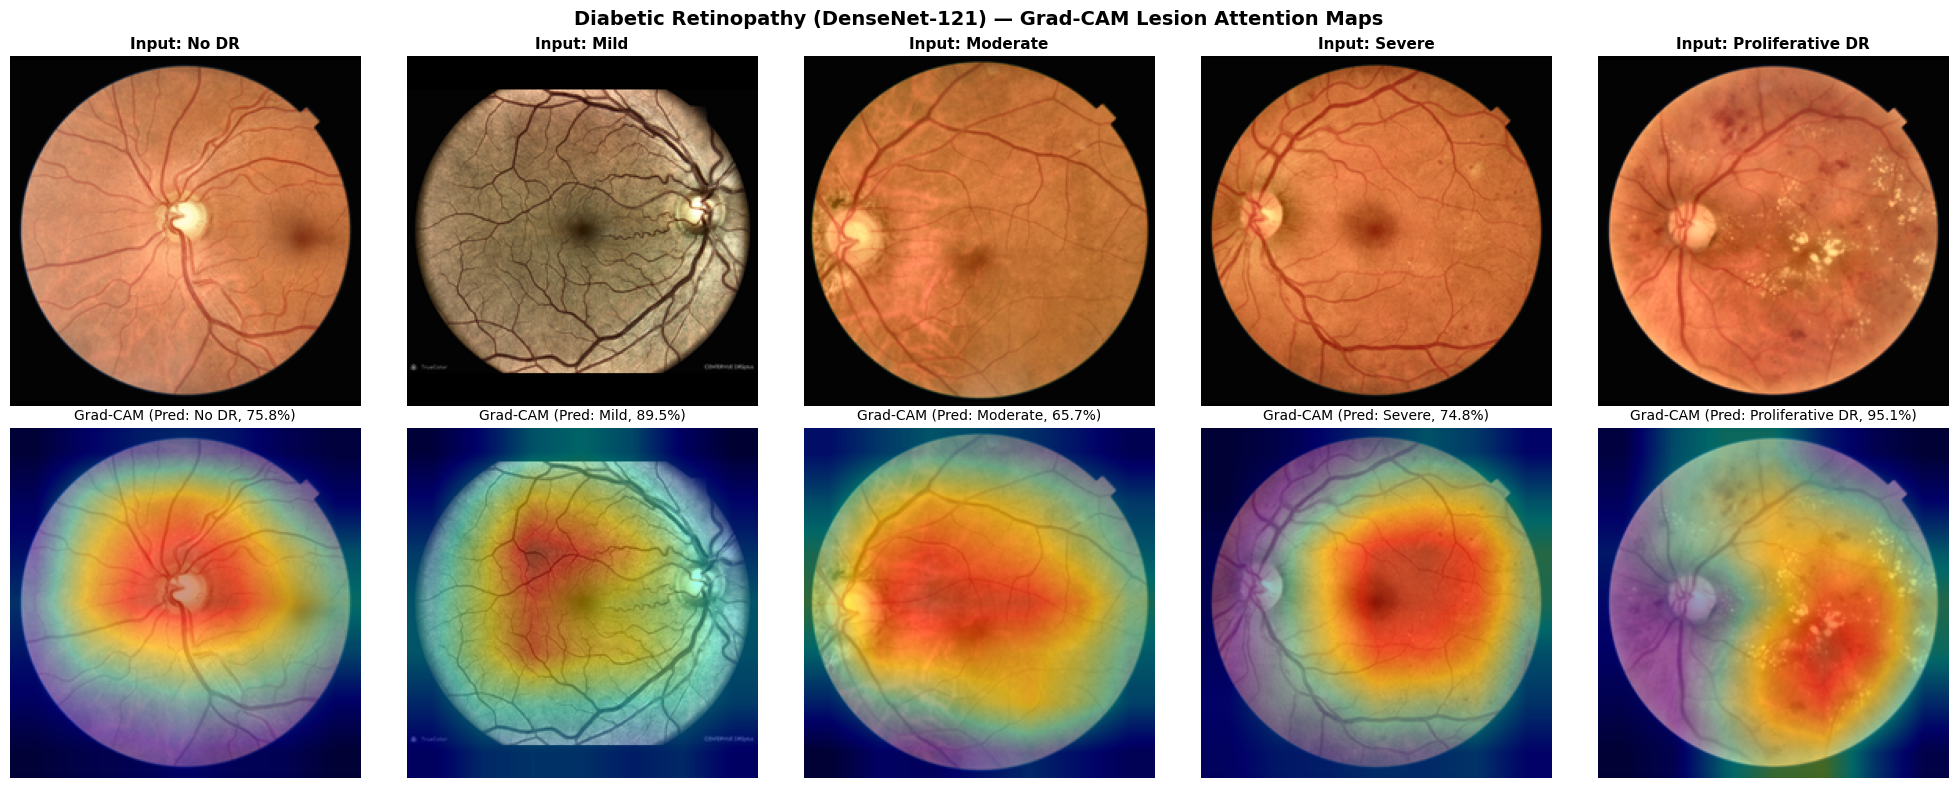

Saved 5-grade Grad-CAM grid and individual overlays to: /content/drive/MyDrive/Major_Project/Diabetic_Retinopathy/outputs/v2/gradcam


In [13]:
# ============================================================
# DR MODULE — GRAD-CAM VISUAL EXPLANATIONS (CHAPTER 5 FIGURES)
# Run directly at the bottom of your active Colab notebook
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torchvision.models import densenet121

# 1. Setup Output Directory
GRADCAM_DIR = V2_DIR / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "Proliferative DR"]

# 2. Load Optimized DenseNet-121 Checkpoint
cam_model = densenet121(weights=None)
cam_model.classifier = nn.Linear(cam_model.classifier.in_features, 5)
cam_model.load_state_dict(
    torch.load(OPT_DIR / "dr_optimized_densenet121_best.pth", map_location=DEVICE, weights_only=True)
)
cam_model = cam_model.to(DEVICE).eval()

# 3. Grad-CAM Hook Class targeting DenseNet-121's final convolutional block
class DenseNetGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._forward_hook)
        target_layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, inp, out):
        self.activations = out.detach()

    def _backward_hook(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def generate(self, input_tensor, target_class=None):
        self.model.zero_grad()
        logits = self.model(input_tensor)
        probs = torch.softmax(logits, dim=1)
        pred_class = int(probs.argmax(dim=1).item())
        confidence = float(probs[0, pred_class].item())

        if target_class is None:
            target_class = pred_class

        score = logits[0, target_class]
        score.backward()

        # Global average pooling of gradients across spatial dimensions
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        # Normalize heatmap to [0, 1]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, pred_class, confidence

gradcam = DenseNetGradCAM(cam_model, cam_model.features.denseblock4)

# 4. Select One Confident Representative Test Sample per DR Grade (Grades 0–4)
pred_df = pd.read_csv(OPT_DIR / "dr_optimized_test_predictions.csv")

norm_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

selected_samples = []
for grade in range(5):
    correct_subset = pred_df[(pred_df["true_grade"] == grade) & (pred_df["predicted_grade"] == grade)].copy()
    if len(correct_subset) > 0:
        prob_col = f"prob_grade_{grade}"
        best_row = correct_subset.sort_values(by=prob_col, ascending=False).iloc[0]
        selected_samples.append(best_row)
    else:
        fallback_row = pred_df[pred_df["true_grade"] == grade].iloc[0]
        selected_samples.append(fallback_row)

# 5. Generate & Save Individual Overlays + Combined 5-Grade Report Grid
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for idx, row in enumerate(selected_samples):
    true_lbl = int(row["true_grade"])
    pil_img = preprocess_dr_v2(row["image_path"])
    rgb_img = np.array(pil_img)

    input_tensor = norm_transform(pil_img).unsqueeze(0).to(DEVICE)
    cam_mask, pred_lbl, conf = gradcam.generate(input_tensor, target_class=true_lbl)

    # Create Jet colormap overlay
    heatmap = cv2.applyColorMap(np.uint8(255 * cam_mask), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(0.60 * rgb_img + 0.40 * heatmap)

    # Save individual high-res overlay image
    indiv_path = GRADCAM_DIR / f"gradcam_grade_{true_lbl}_{CLASS_NAMES[true_lbl].replace(' ', '_')}.png"
    plt.imsave(indiv_path, overlay)

    # Plot Top Row: CLAHE Preprocessed Input
    axes[0, idx].imshow(rgb_img)
    axes[0, idx].set_title(f"Input: {CLASS_NAMES[true_lbl]}", fontsize=11, fontweight="bold")
    axes[0, idx].axis("off")

    # Plot Bottom Row: Grad-CAM Activation Overlay
    axes[1, idx].imshow(overlay)
    axes[1, idx].set_title(
        f"Grad-CAM (Pred: {CLASS_NAMES[pred_lbl]}, {conf*100:.1f}%)",
        fontsize=10
    )
    axes[1, idx].axis("off")

plt.suptitle("Diabetic Retinopathy (DenseNet-121) — Grad-CAM Lesion Attention Maps", fontsize=14, fontweight="bold")
plt.tight_layout()
grid_path = GRADCAM_DIR / "dr_gradcam_5grade_grid.png"
plt.savefig(grid_path, dpi=250, bbox_inches="tight")
plt.show()

print(f"Saved 5-grade Grad-CAM grid and individual overlays to: {GRADCAM_DIR}")

In [14]:
# ============================================================
# DR MODULE — FINAL SUMMARY TABLE & DELTA COMPARISON
# Baseline vs. Optimized vs. Multimodal Fusion (Held-Out Test, n=460)
# ============================================================

import json
import pandas as pd

# 1. Load Saved Held-Out Test Metrics from Each Stage
comp_df = pd.read_csv(OUTPUT_DIR / "dr_model_comparison_test.csv")
opt_df = pd.read_csv(OPT_DIR / "dr_optimized_test_metrics.csv")
fusion_df = pd.read_csv(FUSION_DIR / "dr_fusion_test_metrics.csv")

# Extract Baseline DenseNet-121 row
base_dn = comp_df[comp_df["Architecture"].str.contains("DenseNet")].iloc[0]
base_vit = comp_df[comp_df["Architecture"].str.contains("ViT")].iloc[0]
opt_dn = opt_df.iloc[0]
fus_dn = fusion_df.iloc[0]

# 2. Construct Unified Progression Summary Table
summary_rows = [
    {
        "Stage": "1. Baseline CNN (DenseNet-121)",
        "Accuracy": float(base_dn["Accuracy"]),
        "Balanced Acc": float(base_dn["Balanced Acc"]),
        "Macro Precision": float(base_dn["Macro Precision"]),
        "Macro Recall": float(base_dn["Macro Recall"]),
        "Macro F1": float(base_dn["Macro F1"]),
        "Macro OvR AUROC": float(base_dn["Macro OvR AUROC"]),
        "Multiclass Brier": float(base_dn["Multiclass Brier"]),
    },
    {
        "Stage": "2. Baseline Transformer (ViT-B/16)",
        "Accuracy": float(base_vit["Accuracy"]),
        "Balanced Acc": float(base_vit["Balanced Acc"]),
        "Macro Precision": float(base_vit["Macro Precision"]),
        "Macro Recall": float(base_vit["Macro Recall"]),
        "Macro F1": float(base_vit["Macro F1"]),
        "Macro OvR AUROC": float(base_vit["Macro OvR AUROC"]),
        "Multiclass Brier": float(base_vit["Multiclass Brier"]),
    },
    {
        "Stage": "3. Optimized DenseNet-121 (Label Smoothing 0.1)",
        "Accuracy": float(opt_dn["Accuracy"]),
        "Balanced Acc": float(opt_dn["Balanced Acc"]),
        "Macro Precision": float(opt_dn["Macro Precision"]),
        "Macro Recall": float(opt_dn["Macro Recall"]),
        "Macro F1": float(opt_dn["Macro F1"]),
        "Macro OvR AUROC": float(opt_dn["Macro OvR AUROC"]),
        "Multiclass Brier": float(opt_dn["Multiclass Brier"]),
    },
    {
        "Stage": "4. Multimodal Fusion (DenseNet-121 + Metadata)",
        "Accuracy": float(fus_dn["Accuracy"]),
        "Balanced Acc": float(fus_dn["Balanced Acc"]),
        "Macro Precision": float(fus_dn["Macro Precision"]),
        "Macro Recall": float(fus_dn["Macro Recall"]),
        "Macro F1": float(fus_dn["Macro F1"]),
        "Macro OvR AUROC": float(fus_dn["Macro OvR AUROC"]),
        "Multiclass Brier": float(fus_dn["Multiclass Brier"]),
    }
]

final_summary_df = pd.DataFrame(summary_rows)

# 3. Compute Exact Deltas (Optimized vs. Baseline & Fusion vs. Optimized)
delta_rows = [
    {
        "Comparison": "Optimized DenseNet vs. Baseline DenseNet",
        "Δ Accuracy": round(final_summary_df.loc[2, "Accuracy"] - final_summary_df.loc[0, "Accuracy"], 4),
        "Δ Balanced Acc": round(final_summary_df.loc[2, "Balanced Acc"] - final_summary_df.loc[0, "Balanced Acc"], 4),
        "Δ Macro F1": round(final_summary_df.loc[2, "Macro F1"] - final_summary_df.loc[0, "Macro F1"], 4),
        "Δ Macro AUROC": round(final_summary_df.loc[2, "Macro OvR AUROC"] - final_summary_df.loc[0, "Macro OvR AUROC"], 4),
        "Δ Brier (Lower=Better)": round(final_summary_df.loc[2, "Multiclass Brier"] - final_summary_df.loc[0, "Multiclass Brier"], 4),
    },
    {
        "Comparison": "Multimodal Fusion vs. Optimized DenseNet",
        "Δ Accuracy": round(final_summary_df.loc[3, "Accuracy"] - final_summary_df.loc[2, "Accuracy"], 4),
        "Δ Balanced Acc": round(final_summary_df.loc[3, "Balanced Acc"] - final_summary_df.loc[2, "Balanced Acc"], 4),
        "Δ Macro F1": round(final_summary_df.loc[3, "Macro F1"] - final_summary_df.loc[2, "Macro F1"], 4),
        "Δ Macro AUROC": round(final_summary_df.loc[3, "Macro OvR AUROC"] - final_summary_df.loc[2, "Macro OvR AUROC"], 4),
        "Δ Brier (Lower=Better)": round(final_summary_df.loc[3, "Multiclass Brier"] - final_summary_df.loc[2, "Multiclass Brier"], 4),
    },
    {
        "Comparison": "Multimodal Fusion vs. Baseline DenseNet",
        "Δ Accuracy": round(final_summary_df.loc[3, "Accuracy"] - final_summary_df.loc[0, "Accuracy"], 4),
        "Δ Balanced Acc": round(final_summary_df.loc[3, "Balanced Acc"] - final_summary_df.loc[0, "Balanced Acc"], 4),
        "Δ Macro F1": round(final_summary_df.loc[3, "Macro F1"] - final_summary_df.loc[0, "Macro F1"], 4),
        "Δ Macro AUROC": round(final_summary_df.loc[3, "Macro OvR AUROC"] - final_summary_df.loc[0, "Macro OvR AUROC"], 4),
        "Δ Brier (Lower=Better)": round(final_summary_df.loc[3, "Multiclass Brier"] - final_summary_df.loc[0, "Multiclass Brier"], 4),
    }
]
delta_df = pd.DataFrame(delta_rows)

print("="*95)
print("TABLE 5.X: DIABETIC RETINOPATHY — COMPLETE EXPERIMENTAL PROGRESSION (HELD-OUT TEST, n=460)")
print("="*95)
print(final_summary_df.to_string(index=False))

print("\n" + "="*95)
print("TABLE 5.Y: STAGE-WISE PERFORMANCE DELTAS (Δ)")
print("="*95)
print(delta_df.to_string(index=False))
print("="*95)

# Save to Drive for Report Compilation
final_summary_df.to_csv(OUTPUT_DIR / "dr_final_progression_summary.csv", index=False)
delta_df.to_csv(OUTPUT_DIR / "dr_final_stage_deltas.csv", index=False)
print(f"\nSaved master DR summary tables to: {OUTPUT_DIR}")

TABLE 5.X: DIABETIC RETINOPATHY — COMPLETE EXPERIMENTAL PROGRESSION (HELD-OUT TEST, n=460)
                                          Stage  Accuracy  Balanced Acc  Macro Precision  Macro Recall  Macro F1  Macro OvR AUROC  Multiclass Brier
                 1. Baseline CNN (DenseNet-121)    0.5174        0.5172           0.5136        0.5172    0.5128           0.8521            0.6082
             2. Baseline Transformer (ViT-B/16)    0.5326        0.5375           0.5360        0.5375    0.5330           0.8302            0.6486
3. Optimized DenseNet-121 (Label Smoothing 0.1)    0.5239        0.5159           0.5206        0.5159    0.5079           0.8450            0.5777
 4. Multimodal Fusion (DenseNet-121 + Metadata)    0.5239        0.5269           0.5177        0.5269    0.5204           0.8349            0.6074

TABLE 5.Y: STAGE-WISE PERFORMANCE DELTAS (Δ)
                              Comparison  Δ Accuracy  Δ Balanced Acc  Δ Macro F1  Δ Macro AUROC  Δ Brier (Lower=Better)
Opt